In [1]:
!pip install -q xgboost shap scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from xgboost import XGBClassifier
import shap
import joblib

print("FraudLens environment successfully initialized!")

FraudLens environment successfully initialized!


In [3]:

from google.colab import files

uploaded = files.upload()


Saving creditcard.csv to creditcard (1).csv


In [4]:

df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:

# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null values
print("\nDataset information:")
df.info()

# Statistical summary
print("\nStatistical summary:")
display(df.describe())


Dataset shape: (284807, 31)

Columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [6]:

# Count genuine and fraudulent transactions
class_counts = df["Class"].value_counts()

print("Transaction counts:")
print(class_counts)

print("\nPercentage distribution:")
print(df["Class"].value_counts(normalize=True) * 100)


Transaction counts:
Class
0    284315
1       492
Name: count, dtype: int64

Percentage distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


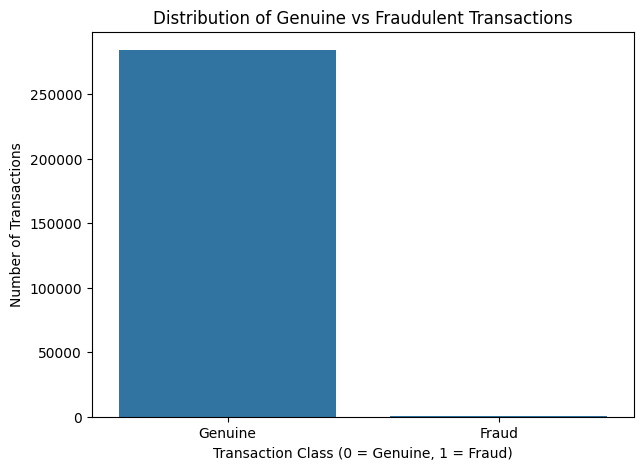

In [7]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Class"
)

plt.title("Distribution of Genuine vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ["Genuine", "Fraud"])
plt.show()


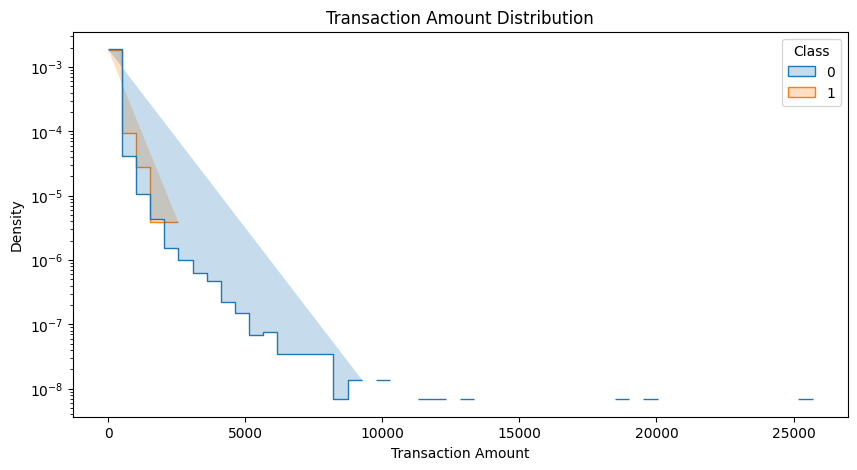

In [8]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=(False, True),
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.show()


In [9]:

print("Genuine transaction amounts:")
display(df[df["Class"] == 0]["Amount"].describe())

print("\nFraudulent transaction amounts:")
display(df[df["Class"] == 1]["Amount"].describe())


Genuine transaction amounts:


,Amount
count,284315.000000
mean,88.291022
std,250.105092
min,0.000000
25%,5.650000
50%,22.000000
75%,77.050000
max,25691.160000



Fraudulent transaction amounts:


,Amount
count,492.000000
mean,122.211321
std,256.683288
min,0.000000
25%,1.000000
50%,9.250000
75%,105.890000
max,2125.870000


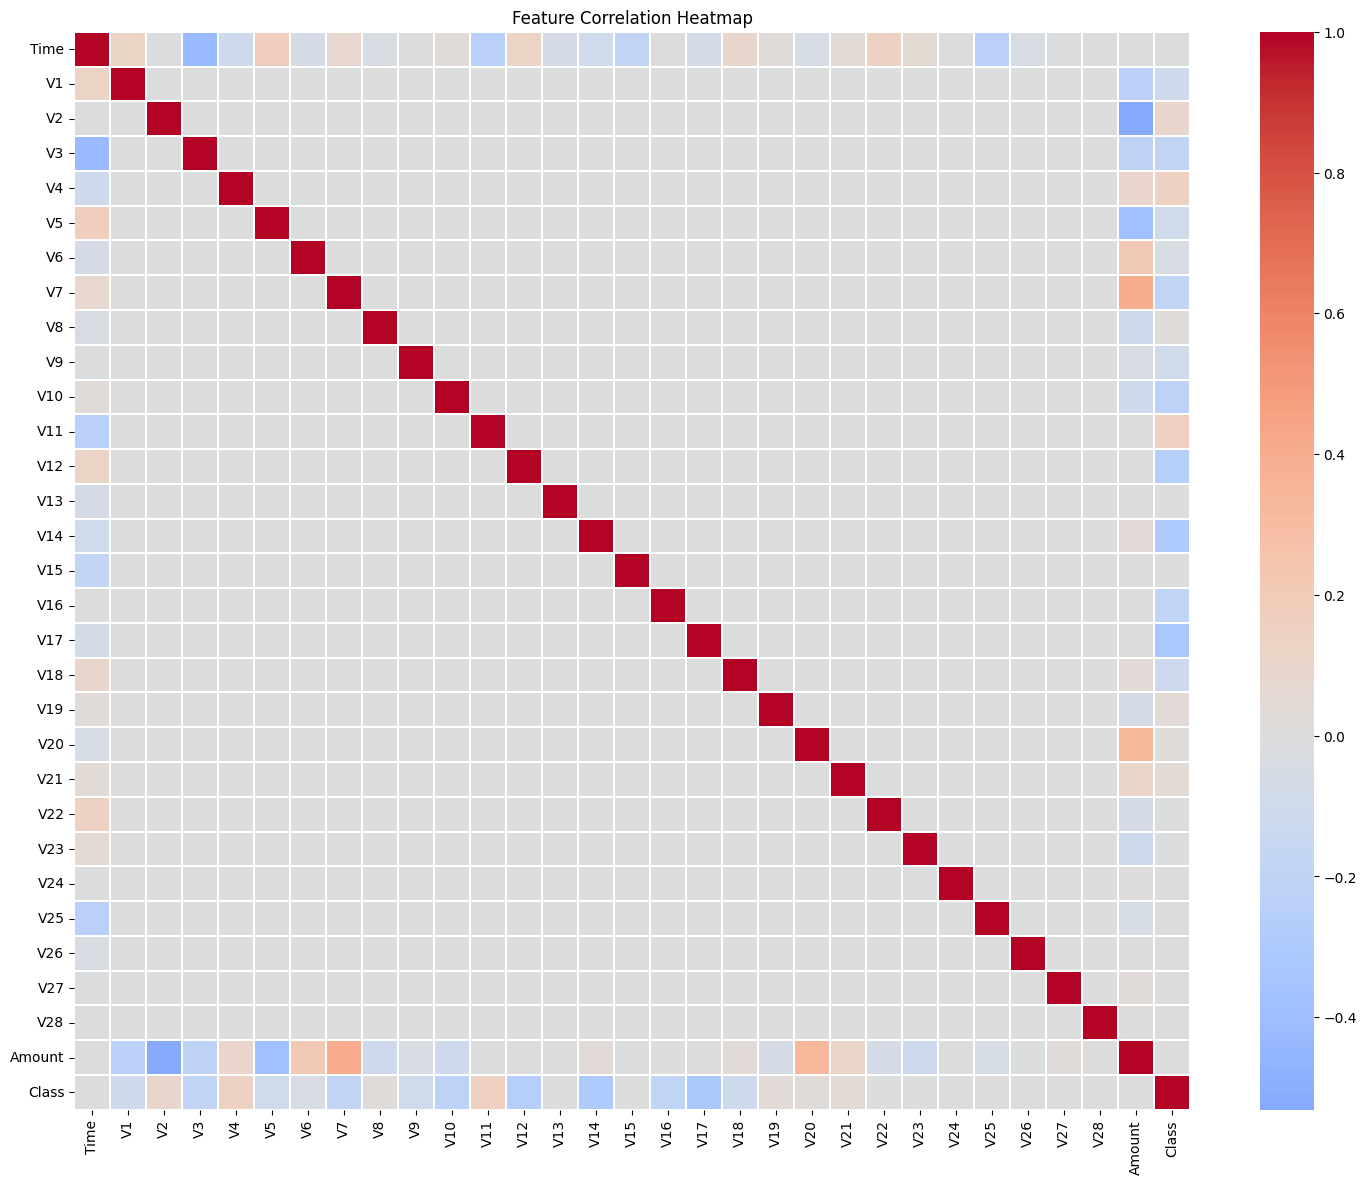

In [10]:

correlation = df.corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Feature Correlation Heatmap")
plt.show()


In [11]:

# Input features
X = df.drop("Class", axis=1)

# Target variable
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (284807, 30)
Target shape: (284807,)


In [12]:

from sklearn.model_selection import train_test_split

# First split: 80% development, 20% testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 70% training, 10% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.125,
    random_state=42,
    stratify=y_train_val
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)


Training set: (199364, 30)
Validation set: (28481, 30)
Testing set: (56962, 30)


In [13]:

print("Fraud distribution across datasets:")

for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name}:")
    print(labels.value_counts())
    print("Fraud percentage:", round(labels.mean() * 100, 4), "%")


Fraud distribution across datasets:

Training:
Class
0    199019
1       345
Name: count, dtype: int64
Fraud percentage: 0.1731 %

Validation:
Class
0    28432
1       49
Name: count, dtype: int64
Fraud percentage: 0.172 %

Testing:
Class
0    56864
1       98
Name: count, dtype: int64
Fraud percentage: 0.172 %


In [14]:

from sklearn.preprocessing import RobustScaler

# Make independent copies
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

# Separate scalers
amount_scaler = RobustScaler()
time_scaler = RobustScaler()

# Fit ONLY on training data
X_train["Amount"] = amount_scaler.fit_transform(
    X_train[["Amount"]]
).ravel()

X_train["Time"] = time_scaler.fit_transform(
    X_train[["Time"]]
).ravel()

# Transform validation data
X_val["Amount"] = amount_scaler.transform(
    X_val[["Amount"]]
).ravel()

X_val["Time"] = time_scaler.transform(
    X_val[["Time"]]
).ravel()

# Transform testing data
X_test["Amount"] = amount_scaler.transform(
    X_test[["Amount"]]
).ravel()

X_test["Time"] = time_scaler.transform(
    X_test[["Time"]]
).ravel()

print("Feature scaling completed!")


Feature scaling completed!


In [15]:

print("Training data:")
display(X_train.head())

print("\nValidation data:")
display(X_val.head())

print("\nTesting data:")
display(X_test.head())

print("\nMissing values in training data:", X_train.isnull().sum().sum())
print("Missing values in validation data:", X_val.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())


Training data:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
60696,-0.416179,1.063504,-0.365659,-0.613548,0.112330,-0.206082,-1.110713,0.550434,-0.341885,0.040144,...,0.175374,-0.001847,-0.377144,-0.267602,-0.055519,0.522903,1.089206,-0.150275,0.009840,1.905159
271628,0.936753,-0.247080,0.914627,-0.526634,-0.792947,1.202472,-0.301877,0.966275,-0.121839,0.261688,...,0.113041,-0.396680,-0.810979,0.125598,0.159868,-0.420032,0.089514,0.048502,-0.104567,-0.170769
108563,-0.163567,1.274645,0.119651,0.171000,0.318736,-0.090453,-0.213795,-0.112079,0.039312,-0.038285,...,-0.105682,-0.269069,-0.849040,0.031174,-0.523868,0.270842,0.131030,-0.039163,-0.001208,-0.278404
141279,-0.007973,0.736977,-1.481626,0.418210,-1.226398,-1.455134,-0.333253,-0.469834,0.079252,1.780510,...,0.436658,0.296637,0.450827,-0.385009,0.066851,0.378246,0.091654,-0.013597,0.054632,3.448755
218141,0.661018,-0.255178,0.121335,-0.926810,-0.630456,2.038403,-1.615679,0.982834,-0.332275,-0.732437,...,0.066052,0.432816,1.153237,-0.055591,-0.324124,-0.737607,0.098717,0.187306,0.253813,-0.287582



Validation data:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
99147,-0.210256,1.108607,-0.070649,1.259236,1.292010,-0.782228,0.273876,-0.627432,0.221471,0.866142,...,-0.155334,-0.032767,0.152445,0.023062,0.088514,0.346750,-0.380094,0.089773,0.035344,-0.167014
127516,-0.076740,-0.695785,0.148657,-0.126689,0.319652,2.185606,4.104523,0.644810,0.889029,-0.669254,...,0.582297,0.020673,-0.238582,0.134988,0.997055,0.430641,-0.210809,0.069948,0.122678,2.239049
220280,0.671798,2.039851,-1.208539,-3.152263,-2.688036,0.102406,-1.811432,0.759350,-0.748657,0.312799,...,-0.314717,0.042935,0.562072,-0.312799,0.667480,0.860716,-0.415921,-0.037638,-0.048412,1.899180
140413,-0.013915,1.274130,-0.068778,-0.174693,-0.796095,-0.236812,-0.919797,0.211108,-0.219294,1.134214,...,-0.160282,0.011231,0.347078,-0.166767,0.134125,0.897401,-0.521466,0.054812,0.008539,-0.292032
235148,0.744240,2.026526,-1.519695,0.121211,-0.651812,-1.614810,0.473900,-1.633398,0.244305,1.110386,...,-0.483623,-0.477252,-0.603982,0.371765,0.620936,-0.690524,1.133377,-0.020808,-0.033619,0.304547



Testing data:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
263020,0.890897,-0.674466,1.408105,-1.110622,-1.328366,1.388996,-1.308439,1.885879,-0.614233,0.311652,...,0.394322,0.080084,0.810034,-0.224327,0.707899,-0.135837,0.045102,0.533837,0.291319,0.013906
11378,-0.763827,-2.829816,-2.765149,2.537793,-1.074580,2.842559,-2.153536,-1.795519,-0.250020,3.073504,...,-0.515765,-0.295555,0.109305,-0.813272,0.042996,-0.027660,-0.910247,0.110802,-0.511938,-0.141149
147283,0.040313,-3.576495,2.318422,1.306985,3.263665,1.127818,2.865246,1.444125,-0.718922,1.874046,...,2.034786,-1.060151,0.016867,-0.132058,-1.483996,-0.296011,0.062823,0.552411,0.509764,0.751912
219439,0.667477,2.060386,-0.015382,-1.082544,0.386019,-0.024331,-1.074935,0.207792,-0.338140,0.455091,...,-0.192024,-0.281684,-0.639426,0.331818,-0.067584,-0.283675,0.203529,-0.063621,-0.060077,-0.292171
36939,-0.541957,1.209965,1.384303,-1.343531,1.763636,0.662351,-2.113384,0.854039,-0.475963,-0.629658,...,0.009083,-0.164015,-0.328294,-0.154631,0.619449,0.818998,-0.330525,0.046884,0.104527,-0.285079



Missing values in training data: 0
Missing values in validation data: 0
Missing values in testing data: 0


In [16]:

# Logistic Regression baseline

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")


Logistic Regression training completed!


In [18]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [19]:

scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

print("Scale positive weight:", scale_pos_weight)

xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")


Scale positive weight: 576.8666666666667
XGBoost training completed!


In [20]:

# Generate fraud probabilities on validation data

lr_probs = lr_model.predict_proba(X_val)[:, 1]
rf_probs = rf_model.predict_proba(X_val)[:, 1]
xgb_probs = xgb_model.predict_proba(X_val)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 XGBoost fraud probabilities:")
print(xgb_probs[:10])


Predictions generated successfully!

First 10 XGBoost fraud probabilities:
[7.38528615e-05 1.18060736e-04 5.36906882e-05 2.33793653e-05
 1.33605572e-05 6.02844921e-05 7.85912678e-04 2.41442176e-04
 3.57125355e-05 1.74620992e-03]


In [21]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

probabilities = {
    "Logistic Regression": lr_probs,
    "Random Forest": rf_probs,
    "XGBoost": xgb_probs
}

results = []

for name, probs in probabilities.items():

    # Use default threshold of 0.5 for initial comparison
    predictions = (probs >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(y_val, probs),
        "ROC-AUC": roc_auc_score(y_val, probs)
    })

results_df = pd.DataFrame(results)

display(
    results_df.round(4).sort_values(
        by="PR-AUC", ascending=False
    )
)


,Model,Precision,Recall,F1-Score,PR-AUC,ROC-AUC
2,XGBoost,0.8636,0.7755,0.8172,0.7961,0.9684
1,Random Forest,0.8372,0.7347,0.7826,0.7557,0.9593
0,Logistic Regression,0.0607,0.8571,0.1134,0.6295,0.9614


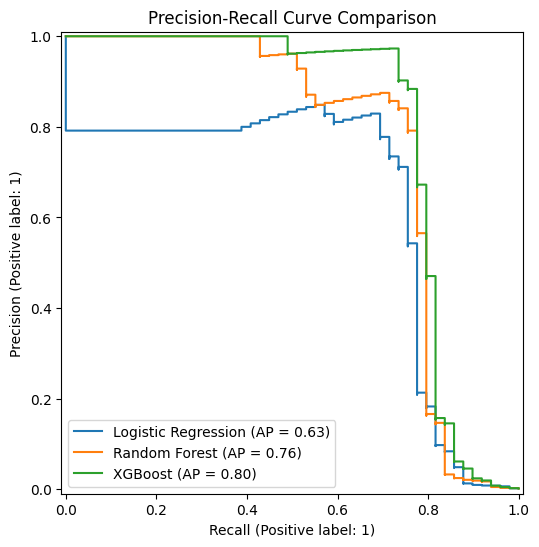

In [22]:

from sklearn.metrics import PrecisionRecallDisplay

plt.figure(figsize=(9, 6))

for name, probs in probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_val,
        probs,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curve Comparison")
plt.show()


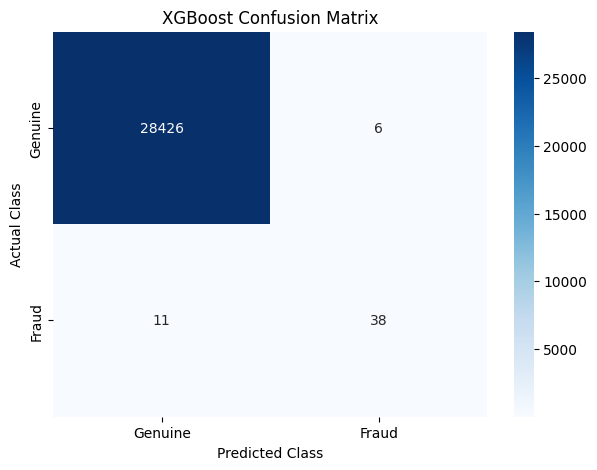

Confusion Matrix:
[[28426     6]
 [   11    38]]


In [23]:

from sklearn.metrics import confusion_matrix

xgb_predictions = (xgb_probs >= 0.5).astype(int)

cm = confusion_matrix(y_val, xgb_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Genuine", "Fraud"],
    yticklabels=["Genuine", "Fraud"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("XGBoost Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


In [24]:

# Baseline cost at threshold 0.5

tn, fp, fn, tp = confusion_matrix(
    y_val, xgb_predictions
).ravel()

baseline_cost = (
    fn * 250 +
    fp * 15 +
    tp * 3
)

print("False Negatives:", fn)
print("False Positives:", fp)
print("True Positives:", tp)
print("Baseline Cost: $", baseline_cost)


False Negatives: 11
False Positives: 6
True Positives: 38
Baseline Cost: $ 2954


In [25]:

import numpy as np
import pandas as pd

thresholds = np.linspace(0.01, 0.99, 99)

threshold_results = []

for threshold in thresholds:

    predictions = (xgb_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions,
        labels=[0, 1]
    ).ravel()

    cost = (
        fn * 250 +
        fp * 15 +
        tp * 3
    )

    threshold_results.append({
        "Threshold": threshold,
        "Cost": cost,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[
    threshold_df["Cost"].idxmin()
]

optimal_threshold = float(best_row["Threshold"])
optimized_cost = float(best_row["Cost"])

print("Optimal Threshold:", round(optimal_threshold, 4))
print("Minimum Estimated Cost: $", optimized_cost)

display(best_row.to_frame().T)


Optimal Threshold: 0.62
Minimum Estimated Cost: $ 2939.0


,Threshold,Cost,TP,FP,FN,Precision,Recall
61,0.62,2939.0,38.0,5.0,11.0,0.883721,0.77551


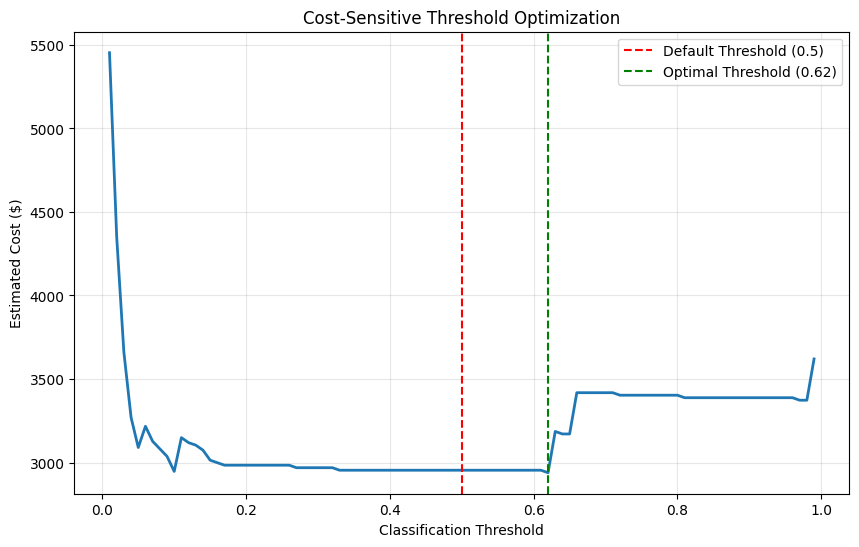

In [26]:

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Cost"],
    linewidth=2
)

plt.axvline(
    x=0.5,
    color="red",
    linestyle="--",
    label="Default Threshold (0.5)"
)

plt.axvline(
    x=optimal_threshold,
    color="green",
    linestyle="--",
    label=f"Optimal Threshold ({optimal_threshold:.2f})"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Estimated Cost ($)")
plt.title("Cost-Sensitive Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [27]:

cost_reduction = (
    (baseline_cost - optimized_cost) /
    baseline_cost
) * 100

print(f"Default Threshold: 0.50")
print(f"Optimized Threshold: {optimal_threshold:.2f}")

print(f"\nBaseline Cost: ${baseline_cost:,.2f}")
print(f"Optimized Cost: ${optimized_cost:,.2f}")

print(f"\nEstimated Cost Reduction: {cost_reduction:.2f}%")


Default Threshold: 0.50
Optimized Threshold: 0.62

Baseline Cost: $2,954.00
Optimized Cost: $2,939.00

Estimated Cost Reduction: 0.51%


In [28]:

# Generate probabilities on unseen test data
xgb_test_probs = xgb_model.predict_proba(X_test)[:, 1]

# Predictions using default threshold
test_pred_default = (xgb_test_probs >= 0.5).astype(int)

# Predictions using frozen optimized threshold
test_pred_optimized = (
    xgb_test_probs >= optimal_threshold
).astype(int)

print("Test predictions generated successfully!")


Test predictions generated successfully!


In [29]:

def evaluate_threshold(y_true, predictions):
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    cost = fn * 250 + fp * 15 + tp * 3

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Estimated Cost": cost
    }

test_results = pd.DataFrame({
    "Default (0.50)": evaluate_threshold(
        y_test, test_pred_default
    ),
    f"Optimized ({optimal_threshold:.2f})": evaluate_threshold(
        y_test, test_pred_optimized
    )
}).T

display(test_results.round(4))


,TP,FP,FN,Precision,Recall,F1,Estimated Cost
Default (0.50),83.0,21.0,15.0,0.7981,0.8469,0.8218,4314.0
Optimized (0.62),82.0,18.0,16.0,0.8200,0.8367,0.8283,4516.0


In [30]:

default_test_cost = test_results.loc[
    "Default (0.50)", "Estimated Cost"
]

optimized_test_cost = test_results.iloc[
    1
]["Estimated Cost"]

test_cost_reduction = (
    (default_test_cost - optimized_test_cost)
    / default_test_cost
) * 100

print(f"Test PR-AUC: {average_precision_score(y_test, xgb_test_probs):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, xgb_test_probs):.4f}")
print(f"Test Cost Reduction: {test_cost_reduction:.2f}%")


Test PR-AUC: 0.8709
Test ROC-AUC: 0.9758
Test Cost Reduction: -4.68%


In [31]:

import shap

# Create SHAP explainer for trained XGBoost model
explainer = shap.TreeExplainer(xgb_model)

# Use a sample of 1000 test transactions
X_shap = X_test.sample(
    n=1000,
    random_state=42
)

# Calculate SHAP values
shap_values = explainer(X_shap)

print("SHAP values calculated successfully!")
print("SHAP shape:", shap_values.values.shape)


SHAP values calculated successfully!
SHAP shape: (1000, 30)


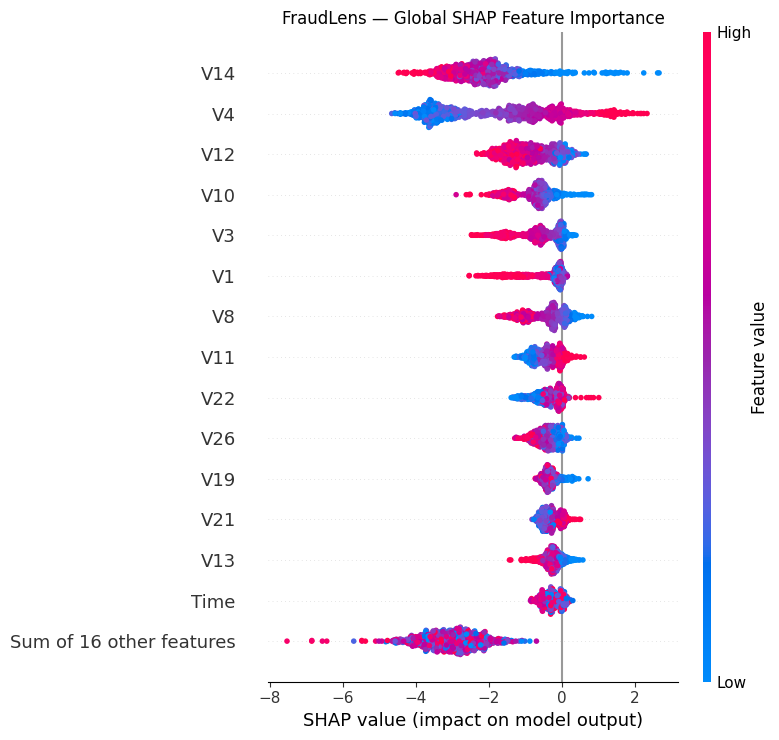

In [32]:

plt.figure(figsize=(10, 8))

shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title("FraudLens — Global SHAP Feature Importance")
plt.tight_layout()
plt.show()


Predicted fraud probability: 0.99991083


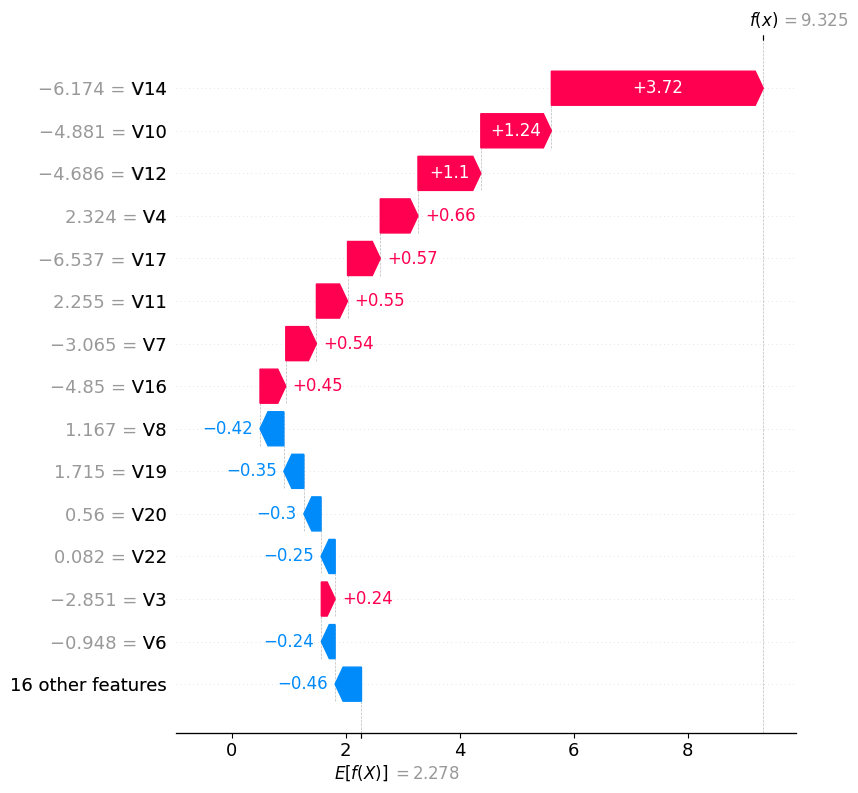

In [33]:

# Find a correctly detected fraudulent transaction
fraud_indices = np.where(
    (y_test.to_numpy() == 1) &
    (test_pred_default == 1)
)[0]

# Select the first correctly detected fraud
fraud_position = fraud_indices[0]

# Get its features
fraud_transaction = X_test.iloc[[fraud_position]]

# Calculate its SHAP values
fraud_shap = explainer(fraud_transaction)

print(
    "Predicted fraud probability:",
    xgb_test_probs[fraud_position]
)

shap.plots.waterfall(
    fraud_shap[0],
    max_display=15
)


In [34]:

import os

os.makedirs("FraudLens/models", exist_ok=True)
os.makedirs("FraudLens/results", exist_ok=True)
os.makedirs("FraudLens/data", exist_ok=True)

print("Project folders created successfully!")


Project folders created successfully!


In [35]:

import joblib

# Save XGBoost model
joblib.dump(
    xgb_model,
    "FraudLens/models/xgb_fraud_model.pkl"
)

# Save preprocessing objects
joblib.dump(
    {
        "amount_scaler": amount_scaler,
        "time_scaler": time_scaler,
        "feature_names": X_train.columns.tolist()
    },
    "FraudLens/models/preprocessing.pkl"
)

# Save the validation-selected threshold
joblib.dump(
    optimal_threshold,
    "FraudLens/models/optimal_threshold.pkl"
)

print("Model, preprocessing and threshold saved!")


Model, preprocessing and threshold saved!


In [36]:

# Save model comparison
results_df.to_csv(
    "FraudLens/results/model_comparison.csv",
    index=False
)

# Save threshold comparison
test_results.to_csv(
    "FraudLens/results/test_threshold_comparison.csv"
)

# Save threshold search results
threshold_df.to_csv(
    "FraudLens/results/threshold_optimization.csv",
    index=False
)

print("Evaluation results saved successfully!")


Evaluation results saved successfully!


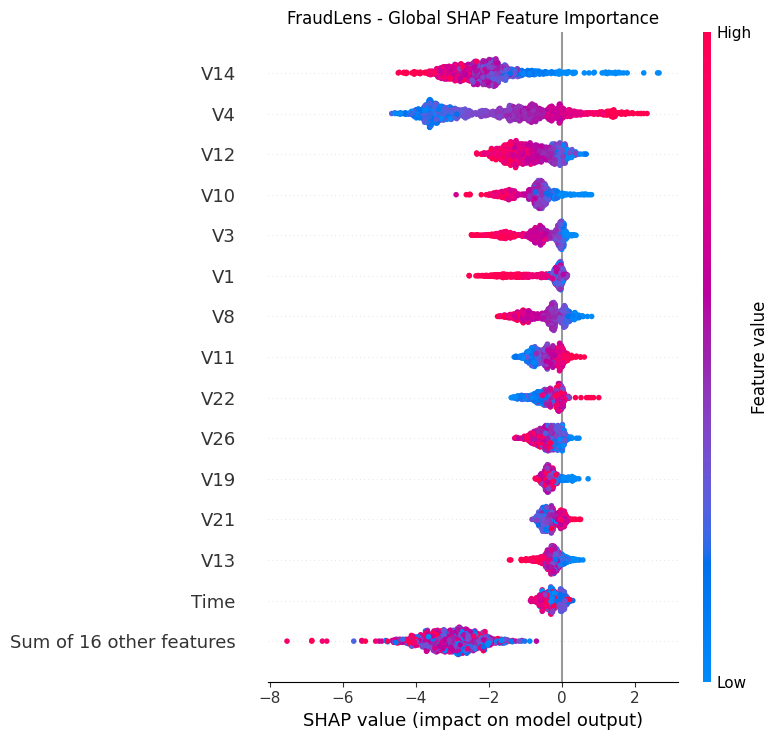

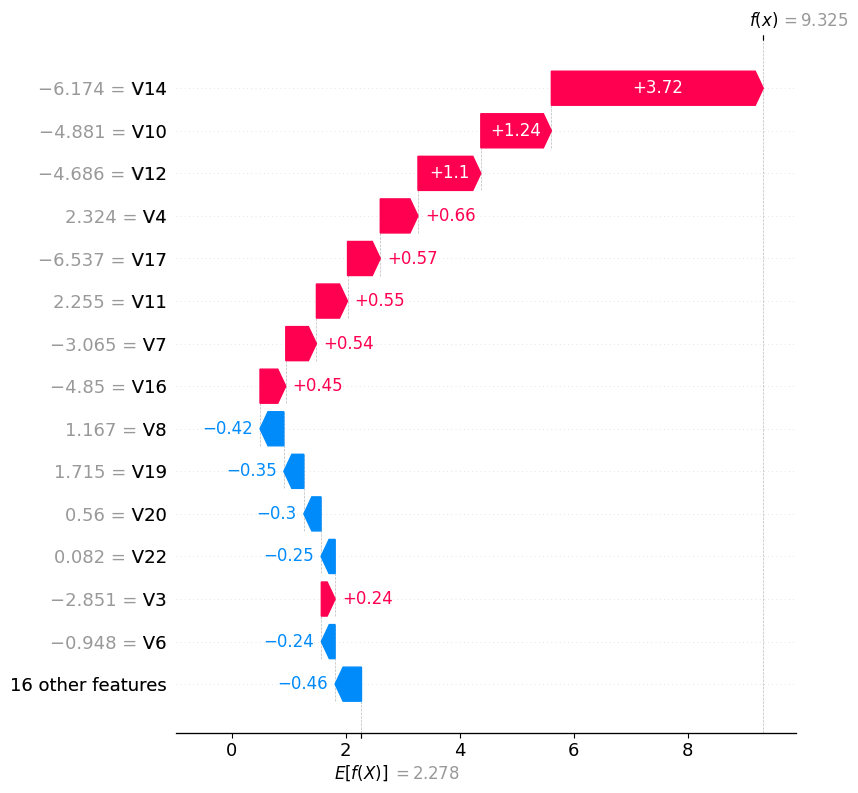

SHAP visualizations saved!


In [37]:

# Global SHAP beeswarm
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.title("FraudLens - Global SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    "FraudLens/results/shap_beeswarm.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Local SHAP waterfall
shap.plots.waterfall(
    fraud_shap[0],
    max_display=15,
    show=False
)

plt.savefig(
    "FraudLens/results/shap_waterfall.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("SHAP visualizations saved!")


In [38]:

# Create a small sample of genuine and fraudulent transactions
sample_genuine = X_test.loc[y_test == 0].sample(
    n=50, random_state=42
)

sample_fraud = X_test.loc[y_test == 1].sample(
    n=30, random_state=42
)

sample_indices = sample_genuine.index.union(
    sample_fraud.index
)

# Use original unscaled feature values
sample_transactions = df.loc[
    sample_indices,
    X.columns
].copy()

sample_transactions["Actual_Class"] = df.loc[
    sample_indices, "Class"
]

sample_transactions.to_csv(
    "FraudLens/data/sample_transactions.csv",
    index=False
)

print("Dashboard sample transactions saved!")
print("Shape:", sample_transactions.shape)


Dashboard sample transactions saved!
Shape: (80, 31)


In [39]:

import shutil
from google.colab import files

shutil.make_archive(
    "FraudLens",
    "zip",
    "FraudLens"
)

files.download("FraudLens.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>